# Fifty Shades of Coffee: дополнительный датасет

Петров Мирон и Каплунова Анна

В [S2](stat-lab1-s2.ipynb) мы проверяли генератор влажности на записях из той же таблицы, из которой рассчитали вероятности. Теперь берём [другую выгрузку Coffee Quality Institute](https://github.com/fatih-boyar/coffee-quality-data-CQI/blob/047db1c5c95e69b7ebad746a66bffd28e8186e3b/df_arabica_clean.csv) и смотрим, насколько профили из S1 описывают более поздние записи. Вероятности по новой выгрузке не подбираем.

### Что во второй таблице

Выгрузку подготовил Фатих Бояр. В ней 207 записей арабики, 41 столбец и 207 разных идентификаторов CQI. Есть страна, дата оценки, влажность, кислотность и полнота напитка. Даты относятся к 2022–2023 годам; даты оценок в нашем поднаборе S1 - к 2010–2018. Источник оценок у обеих таблиц один - CQI, поэтому сравниваем другую выгрузку по времени, а не данные другой лаборатории.

Применяем правило S1: все три показателя должны быть положительными. Одна новая запись с нулевой влажностью исключается, остаётся 206. Сравниваем влажность в процентах: в S1 умножаем значения на 100, во второй таблице значения уже записаны в процентах.

Чтобы пересчитать результаты, запускаем ячейки по порядку. При отсутствии локальных CSV ноутбук скачивает закреплённые версии обоих файлов.

In [ ]:
# Загрузка двух CSV и применение фильтра S1
from hashlib import sha256
from io import BytesIO
from pathlib import Path
from urllib.request import urlopen

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sources = {
    "coffee_ratings.csv": (
        "https://raw.githubusercontent.com/Mironiks007/fifty-shades-of-coffee-stat/"
        "98b9b5e93e7626f2f703dd5c34780db5359bf8a9/coffee_ratings.csv",
        "ae6fdd58f4a7f77397c11c2657e22be8aa8f746bdc5a74cf479e981bd3c25d5e",
    ),
    "coffee-cqi-2023.csv": (
        "https://raw.githubusercontent.com/fatih-boyar/coffee-quality-data-CQI/"
        "047db1c5c95e69b7ebad746a66bffd28e8186e3b/df_arabica_clean.csv",
        "589844ed89b5799989edda3f0aada9b8f5bf5fe75052bc2737eb0c56336f92c0",
    ),
}


def load_csv(name):
    url, expected = sources[name]
    candidates = [Path(folder)/name for folder in (".", "data", "..", "../data")]
    local = next((path for path in candidates if path.is_file()), None)
    if local is not None:
        payload = local.read_bytes()
    else:
        with urlopen(url, timeout=30) as response:
            payload = response.read()
    if sha256(payload).hexdigest() != expected:
        raise ValueError(f"Файл {name} не совпадает с закреплённой версией")
    return pd.read_csv(BytesIO(payload))


old_raw = load_csv("coffee_ratings.csv")
new_raw = load_csv("coffee-cqi-2023.csv")
assert old_raw.shape == (1339, 43) and new_raw.shape == (207, 41)
assert new_raw["ID"].is_unique
new = new_raw.rename(columns={
    "Country of Origin": "country_of_origin", "Grading Date": "grading_date",
    "Moisture Percentage": "moisture", "Acidity": "acidity", "Body": "body",
})
features = ["moisture", "acidity", "body"]
train = old_raw.loc[old_raw.species.eq("Arabica") & old_raw[features].gt(0).all(axis=1)].copy()
test = new.loc[new[features].gt(0).all(axis=1)].copy()
assert len(train) == 1058 and len(test) == 206
train["w"] = (100*train.moisture).round(10)  # убираем только погрешность float
test["w"] = test.moisture


def dates(frame):
    s = frame.grading_date.str.strip().str.replace(r"(\d)(st|nd|rd|th)\b", r"\1", regex=True)
    return pd.to_datetime(s, format="%B %d, %Y")


def describe(frame):
    w = frame.w
    d = dates(frame)
    return {"Записей": len(frame), "Период оценок": f"{d.min():%d.%m.%Y} – {d.max():%d.%m.%Y}",
            "Среднее, %": w.mean(), "Медиана, %": w.median(), "Уровней влажности": w.nunique(),
            "Доля 10–12%, %": 100*w.between(10,12).mean()}


assert dates(train).max() < dates(test).min()
display(pd.DataFrame([describe(train), describe(test)], index=["S1", "CQI 2023"]).round(2))
outside = (~test.w.isin(train.w)).sum()
print(f"В новой выгрузке {outside} из {len(test)} значений отсутствуют на сетке S1.")

В новой выгрузке 182 из 206 значений отсутствуют на сетке S1.


,Записей,Период оценок,"Среднее, %","Медиана, %",Уровней влажности,"Доля 10–12%, %"
S1,1058,09.04.2010 – 19.01.2018,11.00,11.00,22,79.77
CQI 2023,206,11.05.2022 – 28.04.2023,10.79,10.85,45,74.76


### Проверка генератора на новых записях

Берём те же профили, что в S2: общий, Мексика и Гватемала. На записях каждой из этих двух стран сравниваем общий профиль с профилем страны. Другие страны входят в общую сводку новой выгрузки, но в S2 для них нет отдельных режимов.

Сравниваем сами распределения, чтобы результат не зависел от случайного прогона генератора. Для каждой новой записи с влажностью $x$ считаем ту же ошибку CRPS, что и в S2: интеграл квадрата разницы между прогнозом $F(t)$ и фактом того, что $x\le t$. Считаем по ступенькам эмпирических распределений. Меньше ошибка - ближе прогноз к наблюдению. Рядом показываем вероятность 10–12% по каждому профилю и долю таких записей в новой выгрузке.

In [ ]:
# Внешнее сравнение общего профиля с профилями стран
grid = np.union1d(train.w, test.w)


def cdf(values, points):
    values = np.sort(np.asarray(values))
    return np.searchsorted(values, points, side="right") / len(values)


def score(observed, model):
    points = grid[:-1]
    actual = np.asarray(observed)[:, None] <= points
    errors = (cdf(model, points) - actual)**2 @ np.diff(grid)
    return errors.mean()


rows = []
country_names = {"Guatemala": "Гватемала", "Mexico": "Мексика"}
for country, label in country_names.items():
    observed = test.loc[test.country_of_origin.eq(country), "w"]
    conditional = train.loc[train.country_of_origin.eq(country), "w"]
    rows.append({
        "Страна": label, "Записей в проверке": len(observed),
        "10–12%: новые данные, %": 100*observed.between(10, 12).mean(),
        "10–12%: общий профиль, %": 100*train.w.between(10, 12).mean(),
        "10–12%: профиль страны, %": 100*conditional.between(10, 12).mean(),
        "CRPS: общий, п. п.": score(observed, train.w),
        "CRPS: по стране, п. п.": score(observed, conditional),
    })
comparison = pd.DataFrame(rows).set_index("Страна")
display(comparison.round(3))

,Записей в проверке,"10–12%: новые данные, %","10–12%: общий профиль, %","10–12%: профиль страны, %","CRPS: общий, п. п.","CRPS: по стране, п. п."
Страна,,,,,,
Гватемала,21,90.476,79.773,93.103,0.463,0.409
Мексика,4,100.000,79.773,66.667,0.425,0.438


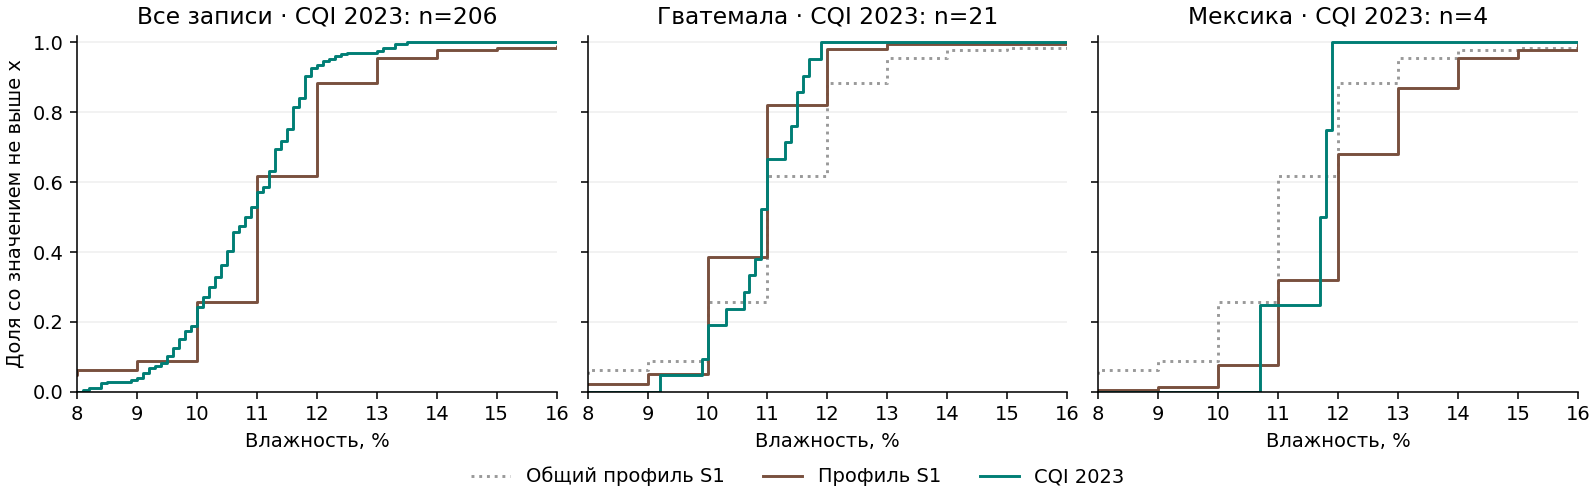

In [ ]:
# Распределения влажности на общей шкале
fig, axes = plt.subplots(1, 3, figsize=(11.4, 3.6), sharex=True, sharey=True, layout="constrained")
for ax, country in zip(axes, [None, "Guatemala", "Mexico"]):
    if country is None:
        current, observed = train.w, test.w
        label = "Все записи"
    else:
        current = train.loc[train.country_of_origin.eq(country), "w"]
        observed = test.loc[test.country_of_origin.eq(country), "w"]
        label = country_names[country]
        ax.step(grid, cdf(train.w, grid), where="post", color="#999999",
                linestyle=":", label="Общий профиль S1")
    ax.step(grid, cdf(current, grid), where="post", color="#79503e", label="Профиль S1")
    ax.step(grid, cdf(observed, grid), where="post", color="#007e75", label="CQI 2023")
    ax.set(xlim=(8, 16), ylim=(0, 1.02), xlabel="Влажность, %",
           title=f"{label} · CQI 2023: n={len(observed)}")
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", alpha=.2)
axes[0].set_ylabel("Доля со значением не выше x")
handles, labels = axes[1].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside lower center", ncol=3, frameon=False)
plt.show()

**Что увидели.** В Гватемале профиль страны дал меньшую ошибку: CRPS снизилась с 0,463 до 0,409 п. п. По модели Гватемалы 93,1% значений попадают в 10–12%; в новой таблице таких записей 19 из 21 (90,5%). Для Мексики получилось наоборот: профиль страны дал чуть большую ошибку, чем общий. Там всего четыре записи, поэтому этот результат не даёт устойчивого вывода о пользе выбора страны.

У 182 из 206 новых записей значение влажности отсутствует среди уровней S1. В S1 встречаются целые проценты, а в новой выгрузке встречаются десятые доли процента. По этим данным нельзя установить точность приборов или причину различия. Генератор из S2 сохраняет сетку S1, поэтому воспроизвести все значения новой выгрузки он не может. Сравнение показывает, где его приближение работает лучше, а где требует новых данных.

### Источники

- Фатих Бояр. [Coffee Quality Data, выгрузка CQI за май 2023 года](https://github.com/fatih-boyar/coffee-quality-data-CQI). [Закреплённый CSV](https://github.com/fatih-boyar/coffee-quality-data-CQI/blob/047db1c5c95e69b7ebad746a66bffd28e8186e3b/df_arabica_clean.csv).
- [S1](stat-lab1-s1.ipynb) - исходный отбор. [S2](stat-lab1-s2.ipynb) - генератор, профили и первое сравнение по CRPS.
- T. Gneiting, A. E. Raftery. [*Strictly Proper Scoring Rules, Prediction, and Estimation*](https://sites.stat.washington.edu/people/raftery/Research/PDF/Gneiting2007jasa.pdf), 2007. Используем интеграл из формулы (20) с положительным знаком, чтобы меньшая ошибка означала лучший прогноз.